# Impact of COVID-19 on ABC Company's Parcel Delivery Business
**Course:** Programming for Data Science - Final Project

**Group Members:** Tirth Patel, Priyank Patel, Nachiket Prajapati, Neel Patel

---
## Objective of the Study
The COVID-19 pandemic changed how people in Canada shopped and worked. Many people started ordering online, so parcel delivery companies were directly affected.

In this notebook we use Python to analyse ABC Company's weekly parcel data and answer:

**Main question:** How did the COVID-19 pandemic impact ABC Company's parcel business?

**Additional questions:**
1. When were customer volumes first impacted by COVID-19?
2. What events within the COVID timeline may have contributed to the change?
3. How did COVID-19 impact peak season in 2020?
4. How has COVID affected the different customer groups (Enterprise, Large, Medium, Small)?
5. What percent of each customer group is growing, moderately growing (stable) and declining?
6. What percent of each customer group are new customers?
7. What percent of 2019 customers in each group did we lose?
8. What was the overall impact of COVID on volumes and revenue by customer group?

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# show numbers with commas so they are easy to read
pd.options.display.float_format = '{:,.2f}'.format

## Step 2: Load the Dataset
The dataset has 4 columns:
* **FakeCustomerID** - customer ID (hidden for privacy)
* **THE_YEAR** - year of shipment
* **THE_WEEK** - week number of the year (1 to 53)
* **VOLUME** - number of parcels shipped by that customer in that week

In [2]:
df = pd.read_csv('COVID_Parcel_Business.csv')
df.head()

,FakeCustomerID,THE_YEAR,THE_WEEK,VOLUME
0,718117,2021,1,8
1,718117,2020,7,257
2,718117,2019,39,141
3,718117,2018,1,14
4,718117,2021,2,192


In [3]:
print('Shape of data (rows, columns):', df.shape)
print()
df.info()

Shape of data (rows, columns): (190719, 4)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190719 entries, 0 to 190718
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   FakeCustomerID  190719 non-null  int64
 1   THE_YEAR        190719 non-null  int64
 2   THE_WEEK        190719 non-null  int64
 3   VOLUME          190719 non-null  int64
dtypes: int64(4)
memory usage: 5.8 MB


## Step 3: Data Cleaning
We check for missing values and duplicate rows (same customer, same year and same week).

In [4]:
print('Missing values in each column:')
print(df.isnull().sum())
print()
duplicates = df.duplicated(subset=['FakeCustomerID', 'THE_YEAR', 'THE_WEEK']).sum()
print('Duplicate customer-week rows:', duplicates)

Missing values in each column:
FakeCustomerID    0
THE_YEAR          0
THE_WEEK          0
VOLUME            0
dtype: int64

Duplicate customer-week rows: 0


**Result:** There are no missing values and no duplicate rows, so the data is clean and ready to use.

## Step 4: Descriptive Statistics

In [5]:
print('Number of unique customers:', df['FakeCustomerID'].nunique())
print('Years in the data:', sorted(df['THE_YEAR'].unique()))
print()
print('Last week available for each year:')
print(df.groupby('THE_YEAR')['THE_WEEK'].max())

Number of unique customers: 1061
Years in the data: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)]

Last week available for each year:
THE_YEAR
2018    53
2019    53
2020    53
2021    39
Name: THE_WEEK, dtype: int64


In [6]:
df['VOLUME'].describe()

count   190,719.00
mean      1,174.91
std      11,586.73
min           1.00
25%          25.00
50%          58.00
75%         162.00
max     640,590.00
Name: VOLUME, dtype: float64

In [7]:
# total parcels and number of active customers for each year
yearly = df.groupby('THE_YEAR').agg(Total_Volume=('VOLUME', 'sum'),
                                    Active_Customers=('FakeCustomerID', 'nunique'))
yearly

,Total_Volume,Active_Customers
THE_YEAR,,
2018,49099478,1025
2019,52823114,1061
2020,73475690,1046
2021,48679668,1014


**Note:** 2021 data is only available until week 39, so 2021 is not a full year. To compare years fairly, we always compare the **same weeks** of each year.

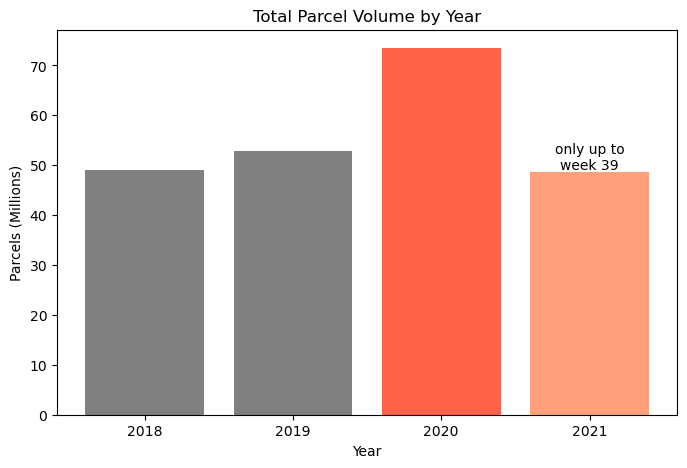

In [8]:
# Bar chart - total parcel volume by year
plt.figure(figsize=(8, 5))
plt.bar(yearly.index.astype(str), yearly['Total_Volume'] / 1_000_000, color=['grey', 'grey', 'tomato', 'lightsalmon'])
plt.title('Total Parcel Volume by Year')
plt.xlabel('Year')
plt.ylabel('Parcels (Millions)')
plt.text(3, yearly.loc[2021, 'Total_Volume'] / 1_000_000 + 0.5, 'only up to\nweek 39', ha='center')
plt.show()

## Step 5: Define the Study Periods
Using the COVID timeline given in the assignment:
* **Jan 27, 2020** - first confirmed case in Canada (week 5)
* **Mar 11, 2020** - WHO declared a pandemic (week 11)
* **Mar 16, 2020** - public servants told to work from home (week 12)
* **Mar 18, 2020** - Canada / U.S. border restrictions (week 12)
* **Mar 23, 2020** - Canada Post COVID delivery standard began (week 13)
* **Apr 6, 2020** - CERB launched (week 15)

So we choose:

| Period | Weeks |
|---|---|
| Pre-COVID observation period | Week 1 to Week 11, 2020 |
| COVID observation period | Week 12 to Week 53, 2020 |

Week 12 is the first week of lockdown measures in Canada.

In [9]:
PRE_COVID_WEEKS = range(1, 12)    # week 1 to 11
COVID_WEEKS = range(12, 54)       # week 12 to 53

PRICE = 22.00   # base price of one parcel (no contract)

## Step 6: Weekly Volume Trend (2019 vs 2020)
To see the impact, we add up all customers' parcels for every week and compare 2020 with 2019.

In [10]:
weekly = df.pivot_table(index='THE_WEEK', columns='THE_YEAR', values='VOLUME', aggfunc='sum')
weekly.head()

THE_YEAR,2018,2019,2020,2021
THE_WEEK,,,,
1,"817,751.00","814,361.00","554,951.00","134,137.00"
2,"925,839.00","1,048,800.00","1,078,417.00","1,583,754.00"
3,"854,760.00","1,073,634.00","1,008,084.00","1,322,546.00"
4,"800,040.00","937,502.00","934,713.00","1,310,292.00"
5,"812,249.00","870,849.00","938,521.00","1,270,718.00"


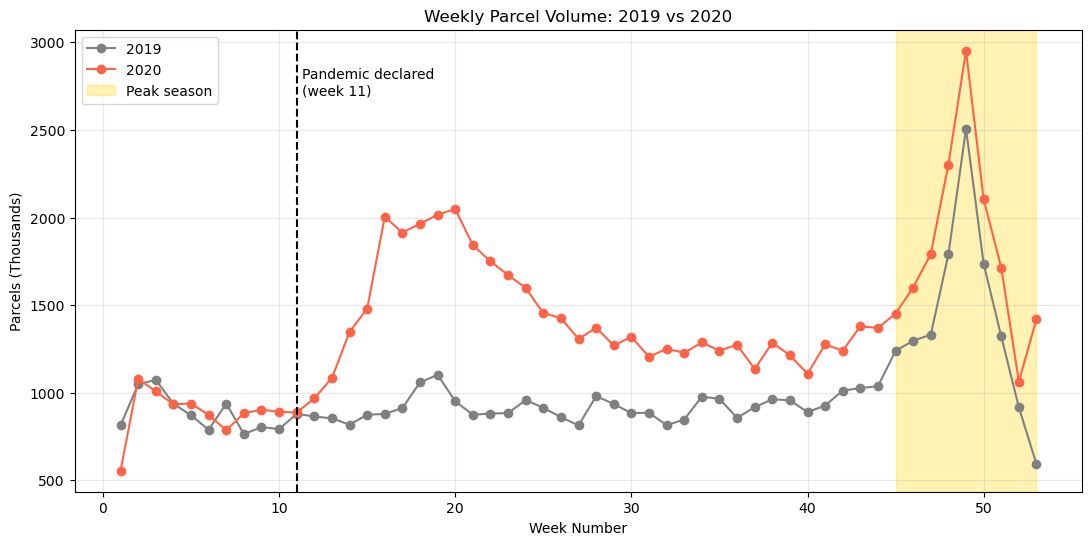

In [11]:
# Line chart - weekly volume 2019 vs 2020
plt.figure(figsize=(13, 6))
plt.plot(weekly.index, weekly[2019] / 1000, marker='o', label='2019', color='grey')
plt.plot(weekly.index, weekly[2020] / 1000, marker='o', label='2020', color='tomato')
plt.axvline(x=11, color='black', linestyle='--')
plt.text(11.3, 2700, 'Pandemic declared\n(week 11)')
plt.axvspan(45, 53, color='gold', alpha=0.3, label='Peak season')
plt.title('Weekly Parcel Volume: 2019 vs 2020')
plt.xlabel('Week Number')
plt.ylabel('Parcels (Thousands)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Observation:** From week 1 to week 11 the two lines are close. After week 12, the 2020 line jumps far above 2019 and stays above for the rest of the year.

## Question 1: When were customer volumes first impacted by COVID-19?
We calculate the **year-over-year (YoY) growth** for each week:

$$YoY\ Growth(\%) = \frac{Volume_{2020} - Volume_{2019}}{Volume_{2019}} \times 100$$

Then we find the first week in 2020 where the growth goes **above the normal range** seen in the pre-COVID weeks.

In [12]:
weekly['YoY_Growth_%'] = (weekly[2020] - weekly[2019]) / weekly[2019] * 100

weekly[[2019, 2020, 'YoY_Growth_%']].loc[1:20]

THE_YEAR,2019,2020,YoY_Growth_%
THE_WEEK,,,
1,"814,361.00","554,951.00",-31.85
2,"1,048,800.00","1,078,417.00",2.82
3,"1,073,634.00","1,008,084.00",-6.11
4,"937,502.00","934,713.00",-0.30
5,"870,849.00","938,521.00",7.77
6,"788,670.00","873,763.00",10.79
7,"938,386.00","786,626.00",-16.17
8,"764,078.00","882,633.00",15.52
9,"803,745.00","903,362.00",12.39


In [13]:
# highest weekly growth seen before COVID (week 1 to 11)
normal_max = weekly.loc[PRE_COVID_WEEKS, 'YoY_Growth_%'].max()
print(f'Highest weekly growth before COVID (week 1-11): {normal_max:.1f}%')

# first week after week 11 that is above this normal range
after_covid = weekly.loc[COVID_WEEKS]
first_week = after_covid[after_covid['YoY_Growth_%'] > normal_max].index[0]
print(f'First week impacted by COVID-19: Week {first_week} of 2020 '
      f'(growth = {weekly.loc[first_week, "YoY_Growth_%"]:.1f}%)')

Highest weekly growth before COVID (week 1-11): 15.5%
First week impacted by COVID-19: Week 13 of 2020 (growth = 27.1%)


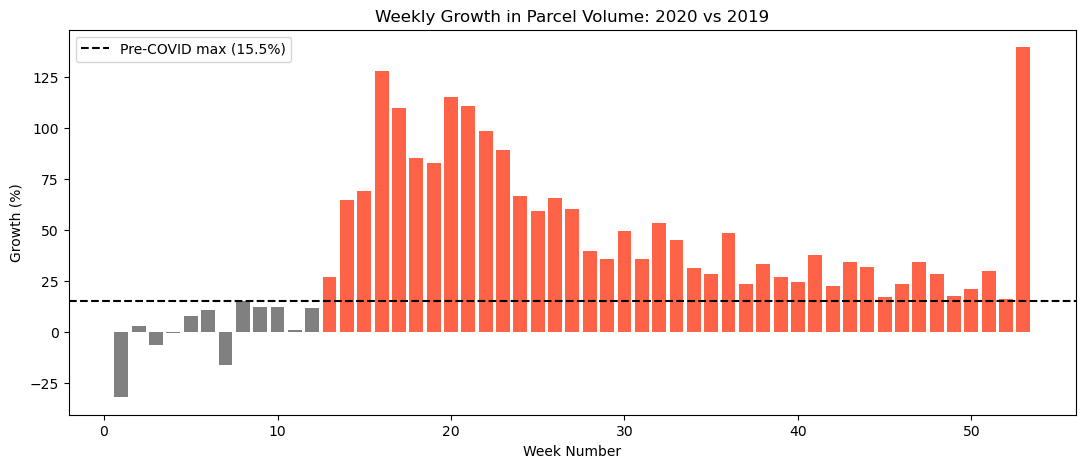

In [14]:
# Bar chart - weekly growth, coloured by period
colors = ['grey' if w < first_week else 'tomato' for w in weekly.index]
plt.figure(figsize=(13, 5))
plt.bar(weekly.index, weekly['YoY_Growth_%'], color=colors)
plt.axhline(y=normal_max, color='black', linestyle='--', label=f'Pre-COVID max ({normal_max:.1f}%)')
plt.title('Weekly Growth in Parcel Volume: 2020 vs 2019')
plt.xlabel('Week Number')
plt.ylabel('Growth (%)')
plt.legend()
plt.show()

**Answer:** Customer volumes were first impacted in **week 13 of 2020 (March 22 - 28, 2020)**. Growth went from about 12% in week 12 to about 27% in week 13, and then 65% in week 14. The biggest jump was in **week 16 (about +128%)**.

*(Week 1 is negative because 2020 week 1 had only 4 days. Week 53 is very high because 2020 week 53 has more days than 2019 week 53. These two weeks are calendar effects, not COVID.)*

## Question 2: What events may have contributed to the change?

In [15]:
events = pd.DataFrame({
    'Week': [5, 11, 12, 12, 13, 15],
    'Event': ['First confirmed case in Canada (Jan 27)',
              'Pandemic declared by WHO (Mar 11)',
              'Public servants urged to work from home (Mar 16)',
              'Canada / U.S. border restrictions (Mar 18)',
              'Canada Post COVID delivery standard began (Mar 23)',
              'CERB launched (Apr 6)']
})
events['Growth_that_week_%'] = events['Week'].map(weekly['YoY_Growth_%']).round(1)
events

,Week,Event,Growth_that_week_%
0,5,First confirmed case in Canada (Jan 27),7.80
1,11,Pandemic declared by WHO (Mar 11),0.90
2,12,Public servants urged to work from home (Mar 16),11.90
3,12,Canada / U.S. border restrictions (Mar 18),11.90
4,13,Canada Post COVID delivery standard began (Mar...,27.10
5,15,CERB launched (Apr 6),69.30


**Answer:**
* The first case in January (week 5) did **not** change volumes.
* After the pandemic was declared (week 11), **work-from-home** and **border closures** (week 12) kept people at home, and stores closed. People started shopping online.
* By week 13, the change is clear in the data. **CERB** (week 15) gave people money to spend, and volume reached its highest growth in weeks 16 - 20 (more than double 2019).

## Question 3: How did COVID-19 impact peak season in 2020?
From the assignment dates:
* **2019 peak season:** Nov 4, 2019 to Jan 20, 2020 → week 45 - 53 of 2019 + week 1 - 3 of 2020
* **2020 peak season:** Nov 2, 2020 to Jan 17, 2021 → week 45 - 53 of 2020 + week 1 - 3 of 2021

We use the same weeks for both so the comparison is fair.

In [16]:
def peak_volume(year):
    part1 = df[(df['THE_YEAR'] == year) & (df['THE_WEEK'] >= 45)]['VOLUME'].sum()
    part2 = df[(df['THE_YEAR'] == year + 1) & (df['THE_WEEK'] <= 3)]['VOLUME'].sum()
    return part1 + part2

peak_2019 = peak_volume(2019)
peak_2020 = peak_volume(2020)
peak_growth = (peak_2020 - peak_2019) / peak_2019 * 100

print(f'2019 peak season volume: {peak_2019:,}')
print(f'2020 peak season volume: {peak_2020:,}')
print(f'Change: {peak_growth:.1f}%')

2019 peak season volume: 15,372,691
2020 peak season volume: 19,442,907
Change: 26.5%


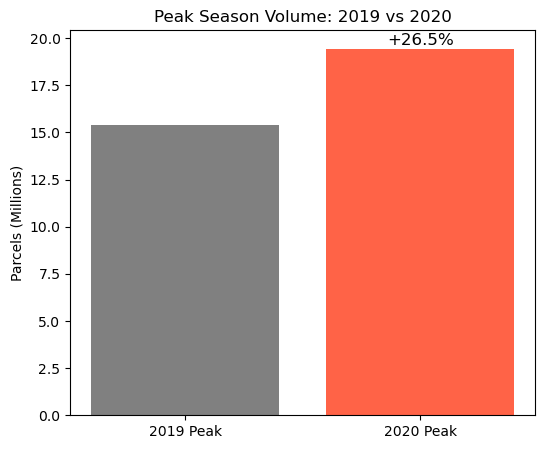

In [17]:
plt.figure(figsize=(6, 5))
plt.bar(['2019 Peak', '2020 Peak'], [peak_2019 / 1_000_000, peak_2020 / 1_000_000], color=['grey', 'tomato'])
plt.title('Peak Season Volume: 2019 vs 2020')
plt.ylabel('Parcels (Millions)')
plt.text(1, peak_2020 / 1_000_000 + 0.2, f'+{peak_growth:.1f}%', ha='center', fontsize=12)
plt.show()

In [18]:
# compare peak season growth with the rest of the COVID period
non_peak_2019 = df[(df['THE_YEAR'] == 2019) & (df['THE_WEEK'].between(12, 44))]['VOLUME'].sum()
non_peak_2020 = df[(df['THE_YEAR'] == 2020) & (df['THE_WEEK'].between(12, 44))]['VOLUME'].sum()
non_peak_growth = (non_peak_2020 - non_peak_2019) / non_peak_2019 * 100
print(f'Growth in COVID weeks 12-44 (before peak): {non_peak_growth:.1f}%')
print(f'Growth in peak season:                     {peak_growth:.1f}%')

Growth in COVID weeks 12-44 (before peak): 55.8%
Growth in peak season:                     26.5%


**Answer:** The 2020 peak season was much bigger than 2019 (see the % above). Peak season in 2020 started from a **higher base** because online shopping stayed high all year. But the peak growth was smaller than the growth in the spring lockdown months, because peak season is always busy (Black Friday, Christmas) even without COVID.

## Step 7: Create Customer Groups
From the assignment, customers are grouped by their **2019 parcel volume**, and each group gets a discount:

| Customer Size | 2019 Parcel Volume | Discount |
|---|---|---|
| Enterprise | more than 500K | 22% |
| Large | 200K - 500K | 17% |
| Medium | 10K - 200K | 10% |
| Small | 1K - 10K | 4% |

The group must be decided **per customer using their total 2019 volume**, not per weekly row.

In [19]:
# total 2019 volume for each customer
customers = df[df['THE_YEAR'] == 2019].groupby('FakeCustomerID')['VOLUME'].sum().reset_index()
customers.columns = ['FakeCustomerID', 'Volume_2019']

def get_group(volume):
    if volume > 500000:
        return 'Enterprise'
    elif volume >= 200000:
        return 'Large'
    elif volume >= 10000:
        return 'Medium'
    elif volume >= 1000:
        return 'Small'
    else:
        return 'Under 1K'

customers['Customer_Group'] = customers['Volume_2019'].apply(get_group)

discounts = {'Enterprise': 0.22, 'Large': 0.17, 'Medium': 0.10, 'Small': 0.04, 'Under 1K': 0.0}
customers['Discount'] = customers['Customer_Group'].map(discounts)

customers.head()

,FakeCustomerID,Volume_2019,Customer_Group,Discount
0,100771,1816,Small,0.04
1,102180,5222,Small,0.04
2,102643,2670,Small,0.04
3,102750,1013,Small,0.04
4,103308,90140,Medium,0.10


In [20]:
group_order = ['Enterprise', 'Large', 'Medium', 'Small']

print('Customers in 2019 data:', len(customers))
print('Customers in full data:', df['FakeCustomerID'].nunique())
print()
print('Number of customers in each group:')
print(customers['Customer_Group'].value_counts().reindex(group_order))

Customers in 2019 data: 1061
Customers in full data: 1061

Number of customers in each group:
Customer_Group
Enterprise     12
Large          15
Medium        174
Small         860
Name: count, dtype: int64


**Note:** All 1,061 customers shipped in 2019 and every one of them shipped at least 1,000 parcels, so every customer fits in one of the four groups.

In [21]:
# add group and discount to the main data
df = df.merge(customers[['FakeCustomerID', 'Customer_Group', 'Discount']], on='FakeCustomerID', how='left')
df.head()

,FakeCustomerID,THE_YEAR,THE_WEEK,VOLUME,Customer_Group,Discount
0,718117,2021,1,8,Small,0.04
1,718117,2020,7,257,Small,0.04
2,718117,2019,39,141,Small,0.04
3,718117,2018,1,14,Small,0.04
4,718117,2021,2,192,Small,0.04


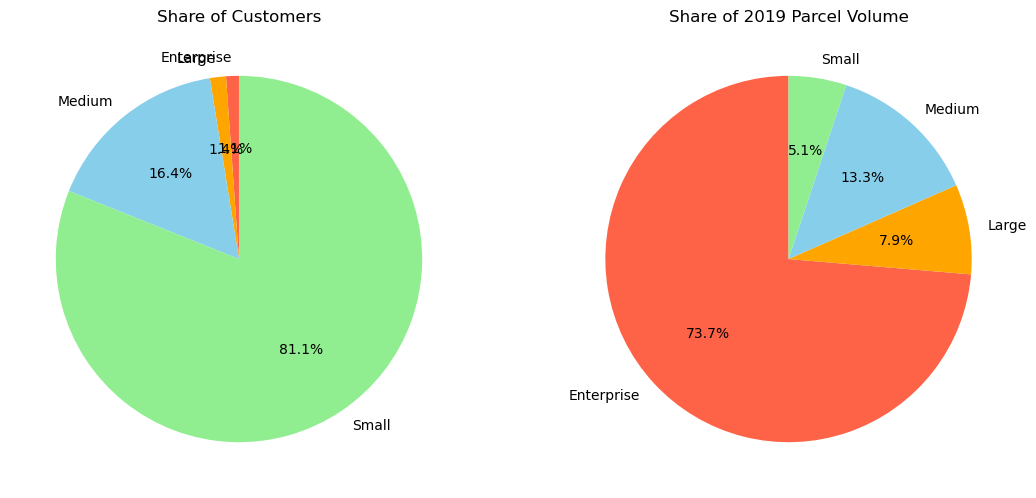

In [22]:
# Pie charts - share of customers vs share of 2019 volume
count_by_group = customers['Customer_Group'].value_counts().reindex(group_order)
volume_by_group = customers.groupby('Customer_Group')['Volume_2019'].sum().reindex(group_order)
pie_colors = ['tomato', 'orange', 'skyblue', 'lightgreen']

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].pie(count_by_group, labels=group_order, autopct='%1.1f%%', colors=pie_colors, startangle=90)
ax[0].set_title('Share of Customers')
ax[1].pie(volume_by_group, labels=group_order, autopct='%1.1f%%', colors=pie_colors, startangle=90)
ax[1].set_title('Share of 2019 Parcel Volume')
plt.show()

**Observation:** Small customers are the majority by count, but the few Enterprise and Large customers ship most of the parcels.

## Step 8: Industry Standard Growth Rate (ISGR)
From the assignment:

$$ISGR(\%) = \frac{Volume_{current} - Volume_{previous}}{Volume_{previous}} \times 100$$

* Current period: week 1 to week 15, 2020
* Previous period: week 1 to week 15, 2019

In [23]:
vol_2020_w1_15 = df[(df['THE_YEAR'] == 2020) & (df['THE_WEEK'].between(1, 15))]['VOLUME'].sum()
vol_2019_w1_15 = df[(df['THE_YEAR'] == 2019) & (df['THE_WEEK'].between(1, 15))]['VOLUME'].sum()

ISGR = (vol_2020_w1_15 - vol_2019_w1_15) / vol_2019_w1_15 * 100
print(f'ISGR = {ISGR:.2f}%')

ISGR = 11.40%


## Step 9: Label Each Customer
For each customer, we compare the **COVID observation period (week 12-53, 2020)** with the **same weeks in 2019**.

| Label | Rule |
|---|---|
| New Customer | 0 parcels in 2019 and early 2020, 1+ parcels in COVID period |
| Lost Customer | 1+ parcels in 2019 / early 2020, 0 parcels in COVID period |
| High Growth (Growing) | growth greater than ISGR |
| Stable (Moderately Growing) | growth between 0% and ISGR |
| Declining | negative growth |

In [24]:
def period_volume(year, weeks):
    data = df[(df['THE_YEAR'] == year) & (df['THE_WEEK'].isin(weeks))]
    return data.groupby('FakeCustomerID')['VOLUME'].sum()

all_ids = df['FakeCustomerID'].unique()
labels = pd.DataFrame(index=all_ids)
labels.index.name = 'FakeCustomerID'

labels['Vol_2019_Full'] = df[df['THE_YEAR'] == 2019].groupby('FakeCustomerID')['VOLUME'].sum()
labels['Vol_2020_PreCOVID'] = period_volume(2020, PRE_COVID_WEEKS)
labels['Vol_2019_SameWeeks'] = period_volume(2019, COVID_WEEKS)
labels['Vol_2020_COVID'] = period_volume(2020, COVID_WEEKS)
labels = labels.fillna(0)

labels['Growth_%'] = (labels['Vol_2020_COVID'] - labels['Vol_2019_SameWeeks']) / labels['Vol_2019_SameWeeks'] * 100
labels.head()

,Vol_2019_Full,Vol_2020_PreCOVID,Vol_2019_SameWeeks,Vol_2020_COVID,Growth_%
FakeCustomerID,,,,,
718117,4425,"2,639.00","3,544.00","8,753.00",146.98
317344,19724,"4,116.00","15,288.00","21,110.00",38.08
631279,1365,304.00,"1,110.00","2,458.00",121.44
226167,1052,249.00,809.00,742.00,-8.28
285685,1128,276.00,772.00,597.00,-22.67


In [25]:
def get_label(row):
    before = row['Vol_2019_Full'] + row['Vol_2020_PreCOVID']
    during = row['Vol_2020_COVID']

    if before == 0 and during > 0:
        return 'New'
    if before > 0 and during == 0:
        return 'Lost'
    if row['Vol_2019_SameWeeks'] == 0:     # shipped nothing in these weeks of 2019, so any volume is growth
        return 'High Growth'
    if row['Growth_%'] > ISGR:
        return 'High Growth'
    if row['Growth_%'] >= 0:
        return 'Stable'
    return 'Declining'

labels['Label'] = labels.apply(get_label, axis=1)
labels = labels.merge(customers[['FakeCustomerID', 'Customer_Group']], left_index=True, right_on='FakeCustomerID', how='left')

print(labels['Label'].value_counts())

Label
High Growth    588
Declining      370
Stable          77
Lost            26
Name: count, dtype: int64


## Question 4 & 5: Growing, Moderately Growing and Declining customers by group

In [26]:
label_order = ['High Growth', 'Stable', 'Declining', 'Lost', 'New']
label_table = pd.crosstab(labels['Customer_Group'], labels['Label'], normalize='index') * 100
label_table = label_table.reindex(index=group_order, columns=label_order, fill_value=0)
label_table.round(1)

Label,High Growth,Stable,Declining,Lost,New
Customer_Group,,,,,
Enterprise,66.70,8.30,25.00,0.00,0
Large,66.70,20.00,13.30,0.00,0
Medium,50.60,10.90,37.90,0.60,0
Small,56.00,6.30,34.80,2.90,0


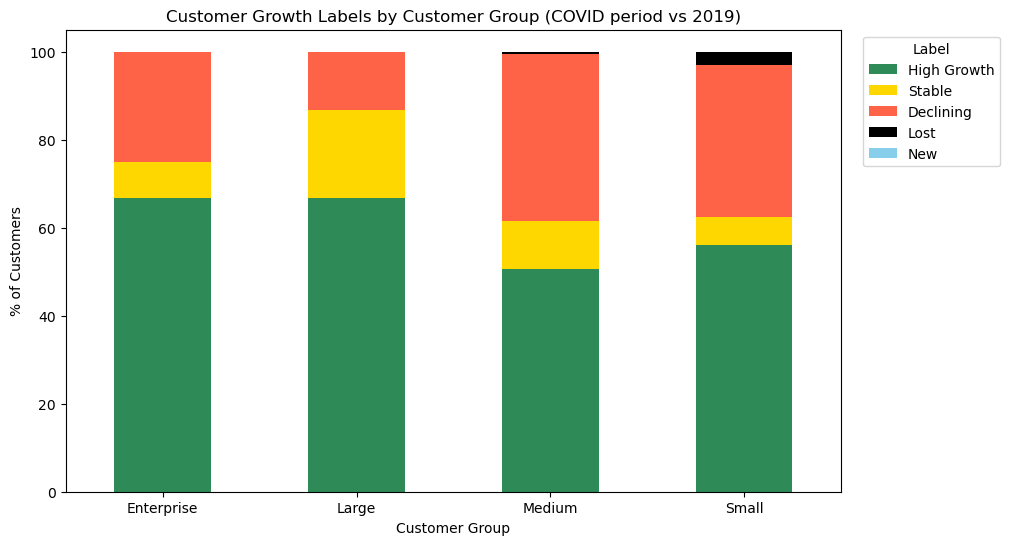

In [27]:
# Stacked bar chart - % of customers in each label, by group
label_table.plot(kind='bar', stacked=True, figsize=(10, 6),
                 color=['seagreen', 'gold', 'tomato', 'black', 'skyblue'])
plt.title('Customer Growth Labels by Customer Group (COVID period vs 2019)')
plt.xlabel('Customer Group')
plt.ylabel('% of Customers')
plt.xticks(rotation=0)
plt.legend(title='Label', bbox_to_anchor=(1.02, 1))
plt.show()

**Answer:**
* **Enterprise:** 66.7% growing, 8.3% moderately growing, 25.0% declining
* **Large:** 66.7% growing, 20.0% moderately growing, 13.3% declining
* **Medium:** 50.6% growing, 10.9% moderately growing, 37.9% declining
* **Small:** 56.0% growing, 6.3% moderately growing, 34.8% declining

In every group, more than half of the customers grew faster than the industry standard rate (ISGR = 11.4%). Large customers did the best, and Medium and Small customers had the most decliners. So COVID helped most businesses, but about 1 in 3 smaller customers shipped less than before.

## Question 6: What percent of each customer group are new customers?

In [28]:
new_pct = label_table['New']
print('Percent of new customers in each group:')
print(new_pct.round(1))
print()
print('Total new customers:', (labels['Label'] == 'New').sum())

Percent of new customers in each group:
Customer_Group
Enterprise    0
Large         0
Medium        0
Small         0
Name: New, dtype: int64

Total new customers: 0


**Answer:** **0% in every group.** All 1,061 customers in the data already shipped with ABC Company in 2019, so no new customers joined during the COVID observation period.

## Question 7: What percent of 2019 customers in each group did we lose?

In [29]:
lost_pct = label_table['Lost']
lost_count = labels[labels['Label'] == 'Lost'].groupby('Customer_Group').size().reindex(group_order, fill_value=0)

lost_summary = pd.DataFrame({'Lost_Customers': lost_count,
                             'Total_Customers': count_by_group,
                             'Lost_%': lost_pct.round(1)})
lost_summary

,Lost_Customers,Total_Customers,Lost_%
Customer_Group,,,
Enterprise,0,12,0.00
Large,0,15,0.00
Medium,1,174,0.60
Small,25,860,2.90


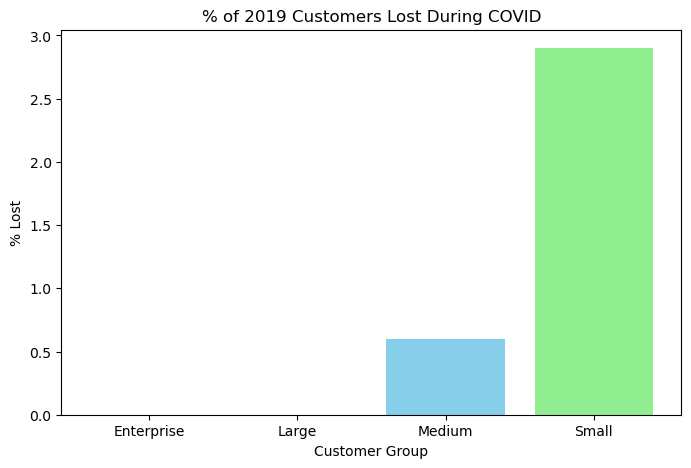

In [30]:
plt.figure(figsize=(8, 5))
plt.bar(group_order, lost_summary['Lost_%'], color=pie_colors)
plt.title('% of 2019 Customers Lost During COVID')
plt.xlabel('Customer Group')
plt.ylabel('% Lost')
plt.show()

**Answer:** We lost **26 customers** in total. That is **0%** of Enterprise and Large customers, **0.6%** of Medium (1 customer) and **2.9%** of Small (25 customers). Only small businesses stopped shipping, probably because some of them closed during the pandemic.

## Question 8: Overall impact of COVID on volume and revenue by group
**Revenue formula:**

$$Revenue = Volume \times \$22 \times (1 - Discount)$$

We compare the COVID observation period (week 12-53, 2020) with the same weeks in 2019.

In [31]:
def group_totals(year):
    data = df[(df['THE_YEAR'] == year) & (df['THE_WEEK'].isin(COVID_WEEKS))].copy()
    data['Revenue'] = data['VOLUME'] * PRICE * (1 - data['Discount'])
    return data.groupby('Customer_Group')[['VOLUME', 'Revenue']].sum().reindex(group_order)

t2019 = group_totals(2019)
t2020 = group_totals(2020)

impact = pd.DataFrame({
    'Volume_2019': t2019['VOLUME'],
    'Volume_2020': t2020['VOLUME'],
    'Revenue_2019': t2019['Revenue'],
    'Revenue_2020': t2020['Revenue'],
})
impact.loc['Total'] = impact.sum()
impact['Volume_Change_%'] = (impact['Volume_2020'] - impact['Volume_2019']) / impact['Volume_2019'] * 100
impact['Revenue_Change_$'] = impact['Revenue_2020'] - impact['Revenue_2019']
impact

,Volume_2019,Volume_2020,Revenue_2019,Revenue_2020,Volume_Change_%,Revenue_Change_$
Customer_Group,,,,,,
Enterprise,"31,978,509.00","46,939,247.00","548,751,214.44","805,477,478.52",46.78,"256,726,264.08"
Large,"3,316,328.00","4,849,447.00","60,556,149.28","88,550,902.22",46.23,"27,994,752.94"
Medium,"5,633,737.00","8,404,819.00","111,547,992.60","166,415,416.20",49.19,"54,867,423.60"
Small,"2,182,136.00","3,542,374.00","46,086,712.32","74,814,938.88",62.34,"28,728,226.56"
Total,"43,110,710.00","63,735,887.00","766,942,068.64","1,135,258,735.82",47.84,"368,316,667.18"


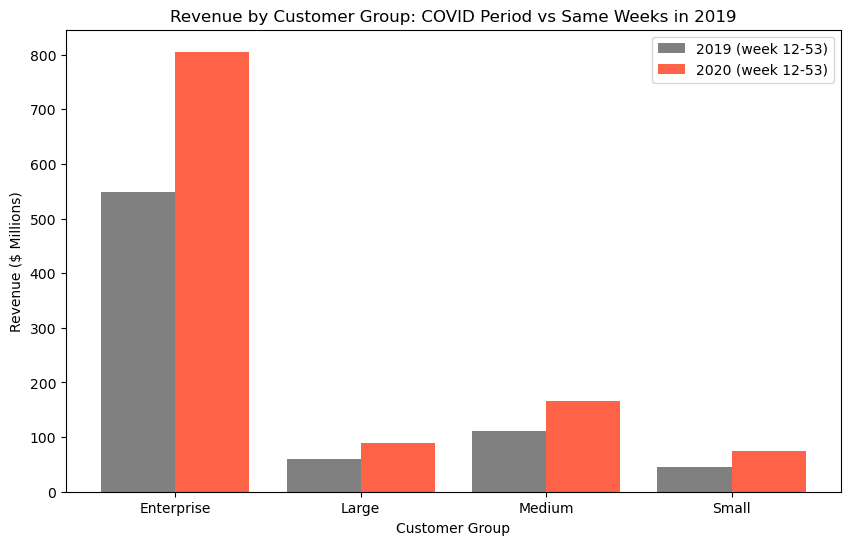

In [32]:
# Grouped bar chart - revenue 2019 vs 2020 by group
x = np.arange(len(group_order))
plt.figure(figsize=(10, 6))
plt.bar(x - 0.2, impact.loc[group_order, 'Revenue_2019'] / 1_000_000, width=0.4, label='2019 (week 12-53)', color='grey')
plt.bar(x + 0.2, impact.loc[group_order, 'Revenue_2020'] / 1_000_000, width=0.4, label='2020 (week 12-53)', color='tomato')
plt.xticks(x, group_order)
plt.title('Revenue by Customer Group: COVID Period vs Same Weeks in 2019')
plt.xlabel('Customer Group')
plt.ylabel('Revenue ($ Millions)')
plt.legend()
plt.show()

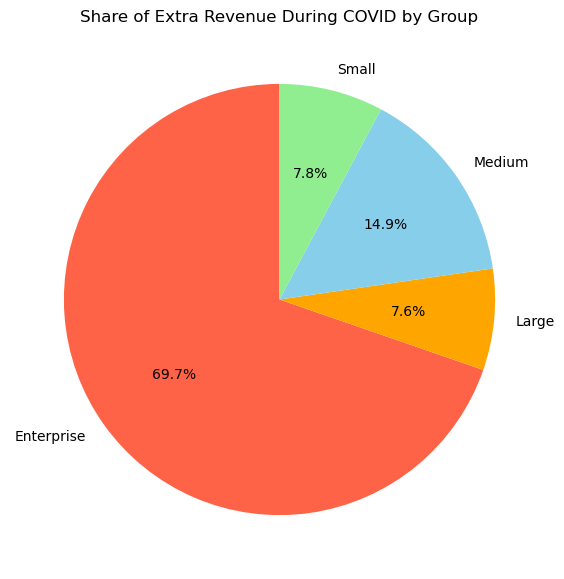

In [33]:
# Pie chart - which group brought the extra revenue
extra = impact.loc[group_order, 'Revenue_Change_$']
plt.figure(figsize=(7, 7))
plt.pie(extra.clip(lower=0), labels=group_order, autopct='%1.1f%%', colors=pie_colors, startangle=90)
plt.title('Share of Extra Revenue During COVID by Group')
plt.show()

In [34]:
total_growth = impact.loc['Total', 'Volume_Change_%']
total_extra = impact.loc['Total', 'Revenue_Change_$']
print(f'Total volume change in COVID period: {total_growth:.1f}%')
print(f'Extra revenue in COVID period:       ${total_extra:,.0f}')

Total volume change in COVID period: 47.8%
Extra revenue in COVID period:       $368,316,667


**Answer:** In the COVID period (week 12-53), total volume went up by **47.8%** and revenue went up by about **$368 million** compared to the same weeks in 2019.
* **Enterprise** brought most of the extra revenue (about $257M, around 70%) because they ship the most parcels.
* **Small** customers grew the fastest (+62.3% volume), even though their total is small.
* **Medium** (+49.2%) and **Large** (+46.2%) also grew strongly.

## Conclusion
**How did COVID-19 impact ABC Company's parcel business?**

* COVID-19 had a **strong positive impact** on ABC Company. Parcel volume and revenue went up a lot in 2020.
* Volume first changed in **week 13 of 2020** (end of March), right after the pandemic declaration, work-from-home orders and border closures.
* The biggest growth was in **April - May 2020** (weeks 16 - 20), when volume was more than **double** of 2019. CERB payments likely helped online spending.
* The **2020 peak season** was also bigger than 2019, but the growth was smaller than in the spring lockdown.
* **No new customers** joined, but more than half of the customers in every group grew faster than the industry standard rate (ISGR = 11.4%). Only 26 customers (all Small or Medium) stopped shipping.
* Total volume in the COVID period went up by **47.8%**, which is about **$368 million** extra revenue. **Enterprise** customers brought around 70% of it, and **Small** customers grew the fastest (+62%).

## Recommendations / Next Steps
1. **Keep the big customers:** Enterprise customers brought most of the extra revenue. Offer them long-term contracts.
2. **Support smaller customers:** about 1 in 3 Medium and Small customers declined, and all lost customers were Small or Medium. Contact them and find out why.
3. **Plan capacity:** volume in 2021 is still higher than 2019, so keep extra trucks and staff for peak season.
4. **Find new customers:** no new customers joined during COVID, so the sales team should target new e-commerce businesses.
5. **Review discounts:** many customers now ship more than their 2019 group, so their contracts and discounts should be updated.